# 17. Teste independente da calibração da API

A prova de conceito do [NB14](14_api_poc.ipynb) usou as mesmas 20.000 consultas para diagnosticar falhas, ajustar os limiares da política de resposta e estimar o erro por classe, e essa avaliação é interna ao ajuste. Este notebook congela a política em execução, sorteia endereços novos do BHMap que não pertencem à amostra de desenvolvimento, separa calibração e teste por blocos espaciais de 2 km e verifica se o erro estimado na calibração vale fora dela.

O notebook exige a API no ar com a carga censal, na porta local 58001, e por isso roda com `run_pipeline.py --com-api`, junto com o NB14. As entradas são `bhmap_bh.parquet`, com os 757.113 pontos de endereço do BHMap, e a amostra de desenvolvimento do NB14. A referência de comparação é o ponto do BHMap, com a mesma ressalva do NB14: o erro medido inclui o deslocamento entre CNEFE e BHMap e o erro de seleção do candidato.

In [1]:
from pathlib import Path
import sys, json, time, hashlib
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import geopandas as gpd
import httpx
import matplotlib.pyplot as plt
from pyproj import Transformer
from sklearn.metrics import roc_auc_score
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/config.py').exists())
sys.path.insert(0, str(ROOT))
from src import config
from src.metrics import chave_identidade
from src.api.calibracao import Calibrador, carregar
P, T, F = config.PROCESSED_DIR, config.TAB_DIR, config.FIG_DIR
for d in [T, F]: d.mkdir(parents=True, exist_ok=True)
RANDOM_STATE = 42
API = 'http://localhost:58001'
BLOCO_M = 2000
N_POR_METADE = 20000
saude = httpx.get(API+'/health', timeout=10).json()
print(saude)
assert saude['status'] == 'ok' and saude['enderecos'] == 590615

{'status': 'ok', 'banco': 'ok', 'enderecos': 590615, 'municipios': 1, 'versao': '2.0.0'}


## 1. Amostras de calibração e de teste

A população são os pontos vistoriados do BHMap, com ou sem placa, com chave de logradouro e número válida. Os pontos a confirmar, números concedidos que o CTM ainda não vistoriou, ficam fora, porque só um ponto verificado em campo serve de referência para calibrar distâncias. Saem dela todas as chaves presentes nas 20.000 consultas de desenvolvimento, para que nenhum endereço usado no ajuste dos limiares volte ao teste. Os blocos de 2 km são sorteados em duas metades. Endereços de um bloco pertencem todos à mesma metade, o que impede que vizinhos imediatos fiquem um na calibração e outro no teste. A amostra de desenvolvimento cobre a cidade inteira, então a independência em relação a ela é por endereço, não por espaço.

In [2]:
bh_total = gpd.read_parquet(P/'bhmap_bh.parquet')
bh = bh_total[bh_total.EXISTENCIA.ne('a confimar')].copy()
assert len(bh) == 683730
log_b, num_b = chave_identidade(bh.SIGLA_TIPO.fillna('')+' '+bh.NOME_LOGRA.fillna(''), bh.NUMERO_IMO)
bh['chave'] = (log_b.astype('string')+'|'+num_b.astype('string')).where(log_b.notna() & log_b.ne('') & num_b.notna()).to_numpy()
dev = pd.read_csv(ROOT/'scratch/baseline/input_bh.csv')
log_d, num_d = chave_identidade(dev.logradouro, dev.numero)
chaves_dev = set((log_d.astype('string')+'|'+num_d.astype('string')).dropna())
pop = bh[bh.chave.notna() & ~bh.chave.isin(chaves_dev)].copy()
pop['bloco'] = (pop.geometry.x//BLOCO_M).astype(int).astype(str)+'_'+(pop.geometry.y//BLOCO_M).astype(int).astype(str)
blocos = np.array(sorted(pop.bloco.unique()))
rng = np.random.default_rng(RANDOM_STATE)
calib_blocos = set(rng.permutation(blocos)[:len(blocos)//2])
pop['metade'] = np.where(pop.bloco.isin(calib_blocos), 'calibracao', 'teste')
amostra = pd.concat([g.sample(N_POR_METADE, random_state=RANDOM_STATE) for _, g in pop.groupby('metade')])
assert not amostra.chave.isin(chaves_dev).any()
assert amostra.groupby('bloco').metade.nunique().max() == 1
desenho = pd.DataFrame([
    {'etapa': 'BHMap, todos os pontos', 'n': len(bh_total)},
    {'etapa': 'pontos vistoriados (com ou sem placa)', 'n': len(bh)},
    {'etapa': 'com chave valida', 'n': int(bh.chave.notna().sum())},
    {'etapa': 'chaves da amostra de desenvolvimento', 'n': len(chaves_dev)},
    {'etapa': 'populacao elegivel, sem chaves de desenvolvimento', 'n': len(pop)},
    {'etapa': 'blocos de 2 km', 'n': len(blocos)},
    {'etapa': 'blocos de calibracao', 'n': len(calib_blocos)},
    {'etapa': 'blocos de teste', 'n': len(blocos)-len(calib_blocos)},
    {'etapa': 'populacao na metade de calibracao', 'n': int(pop.metade.eq('calibracao').sum())},
    {'etapa': 'populacao na metade de teste', 'n': int(pop.metade.eq('teste').sum())},
    {'etapa': 'amostra de calibracao', 'n': N_POR_METADE}, {'etapa': 'amostra de teste', 'n': N_POR_METADE}])
desenho.to_csv(T/'nb17_desenho_amostral.csv', index=False)
print(desenho.to_string(index=False))

                                            etapa      n
                           BHMap, todos os pontos 757113
            pontos vistoriados (com ou sem placa) 683730
                                 com chave valida 683730
             chaves da amostra de desenvolvimento  19798
populacao elegivel, sem chaves de desenvolvimento 653377
                                   blocos de 2 km    109
                             blocos de calibracao     54
                                  blocos de teste     55
                populacao na metade de calibracao 348428
                     populacao na metade de teste 304949
                            amostra de calibracao  20000
                                 amostra de teste  20000


## 2. Consultas à política congelada

Cada consulta tem a mesma forma do NB14: tipo e nome do logradouro, número e bairro. A política em execução é identificada pelo hash `versao_politica` que a própria resposta devolve, e o conjunto de dados por `versao_dados`. O notebook exige que os dois sejam únicos em todas as respostas, o que comprova que limiares e carga não mudaram durante o teste. O erro é a distância entre a coordenada devolvida e o ponto do BHMap, em SIRGAS 2000 / UTM 23S.

In [3]:
cliente = httpx.Client(base_url=API, timeout=30, limits=httpx.Limits(max_connections=16))
def consultar(linha):
    texto = f"{linha.SIGLA_TIPO} {linha.NOME_LOGRA}, {int(linha.NUMERO_IMO)}, {linha.NOME_BAIRR}"
    t0 = time.perf_counter()
    r = cliente.post('/geocode', json={'endereco': texto, 'municipio': 'Belo Horizonte', 'limite': 1})
    ms = (time.perf_counter()-t0)*1000
    base = {'idx': linha.Index, 'status_http': r.status_code, 'latencia_ms': ms}
    corpo = r.json() if r.status_code == 200 else {}
    if not corpo.get('candidatos'):
        return {**base, 'nivel': 'sem_resposta', 'confianca': 'sem_resposta'}
    m = corpo['candidatos'][0]; q = m['qualidade']
    return {**base, 'lat': m['latitude'], 'lon': m['longitude'], 'nivel': m['nivel_precisao'],
            'confianca': q['confianca_posicional'], 'identidade': q['incerteza_identidade'],
            'similaridade': m['similaridade_logradouro'], 'versao_dados': m['versao_dados'],
            'versao_politica': q['calibracao']['versao_politica'], 'status_calibracao': q['calibracao']['status']}
inicio = time.perf_counter()
with ThreadPoolExecutor(max_workers=8) as ex:
    resp = pd.DataFrame(list(ex.map(consultar, amostra.itertuples())))
decorrido = time.perf_counter()-inicio
resp = resp.set_index('idx').join(amostra[['metade','bloco']].assign(xr=amostra.geometry.x, yr=amostra.geometry.y))
para_utm = Transformer.from_crs('EPSG:4326', bh.crs, always_xy=True)
ok = resp.lat.notna()
x, y = para_utm.transform(resp.loc[ok,'lon'].to_numpy(), resp.loc[ok,'lat'].to_numpy())
resp.loc[ok,'erro_m'] = np.hypot(x-resp.loc[ok,'xr'].to_numpy(), y-resp.loc[ok,'yr'].to_numpy())
politicas, versoes = resp.versao_politica.dropna().unique(), resp.versao_dados.dropna().unique()
assert len(politicas) == 1 and len(versoes) == 1, (politicas, versoes)
assert resp.status_http.isin([200, 404]).all(), resp.status_http.value_counts()
VERSAO_POLITICA, VERSAO_DADOS = politicas[0], versoes[0]
print(f'{len(resp):,} consultas em {decorrido:.0f} s, {1000*decorrido/len(resp):.1f} ms por consulta com 8 em paralelo')
print('HTTP', resp.status_http.value_counts().to_dict(), '| status de calibracao', resp.status_calibracao.value_counts(dropna=False).to_dict())
print('versao_politica', VERSAO_POLITICA); print('versao_dados', VERSAO_DADOS)
resp.drop(columns=['lat','lon','xr','yr']).to_csv(T/'nb17_medicoes.csv')

40,000 consultas em 290 s, 7.2 ms por consulta com 8 em paralelo
HTTP {200: 39804, 404: 196} | status de calibracao {'calibrada': 39804, nan: 196}
versao_politica 343916723a8e9266725be6aaa12068cbd7c3ca242c524b1cb4ad0c304266dac4
versao_dados 08dc7c7c149e767cebad336cef11fd73d2c061ec2a3ff830dd06f61b09c37d78


## 3. A calibração vale fora da amostra em que foi estimada?

A tabela é estimada só na metade de calibração, com a mesma regra da API: células com menos de 100 casos não entram, e a resposta recua para o nível ou para o global. Na metade de teste, mede-se a cobertura: a fração dos erros que fica abaixo da mediana e do P90 estimados na calibração. Uma calibração que vale fora da amostra produz cobertura próxima de 50% e de 90%. Os intervalos vêm de 1.000 reamostragens por bloco espacial da metade de teste.

In [4]:
def estatisticas(e):
    e = np.asarray(e, float)
    return {'n': len(e), 'erro_mediano_m': float(np.median(e)), 'erro_ce90_m': float(np.quantile(e, .9)),
            'acima_30_pct': 100*float((e > 30).mean()), 'acima_100_pct': 100*float((e > 100).mean())}
medido = resp[resp.erro_m.notna()]
cal, tes = medido[medido.metade == 'calibracao'], medido[medido.metade == 'teste']
linhas = [{'nivel': '', 'confianca': '', 'base': 'global', **estatisticas(cal.erro_m)}]
for nv, g in cal.groupby('nivel'):
    linhas.append({'nivel': nv, 'confianca': '', 'base': 'nivel', **estatisticas(g.erro_m)})
for (nv, cf), g in cal.groupby(['nivel','confianca']):
    linhas.append({'nivel': nv, 'confianca': cf, 'base': 'nivel+confianca', **estatisticas(g.erro_m)})
tabela = pd.DataFrame(linhas)
tabela = tabela[tabela.n >= 100].reset_index(drop=True)
def celula(nv, cf):
    for k in [(nv, cf), (nv, ''), ('', '')]:
        l = tabela[(tabela.nivel == k[0]) & (tabela.confianca == k[1])]
        if len(l): return l.iloc[0]
tes = tes.copy()
cel = [celula(nv, cf) for nv, cf in zip(tes.nivel, tes.confianca)]
tes['med_cal'] = [c.erro_mediano_m for c in cel]; tes['ce90_cal'] = [c.erro_ce90_m for c in cel]
tes['base_usada'] = [c.base for c in cel]
tes['abaixo_med'] = tes.erro_m <= tes.med_cal; tes['abaixo_ce90'] = tes.erro_m <= tes.ce90_cal
tes = tes.reset_index()
posicoes = [np.asarray(v) for v in tes.groupby('bloco').indices.values()]
rng = np.random.default_rng(RANDOM_STATE)
def ic_bloco(func, reps=1000):
    vals = []
    for _ in range(reps):
        b = rng.integers(len(posicoes), size=len(posicoes))
        vals.append(func(tes.iloc[np.concatenate([posicoes[k] for k in b])]))
    return np.percentile(vals, [2.5, 97.5])
cobertura = []
for nome, g in [('global', tes)] + [(nv, g) for nv, g in tes.groupby('nivel')]:
    filtro = (lambda s: s) if nome == 'global' else (lambda s, nv=nome: s[s.nivel == nv])
    ic_med = ic_bloco(lambda s: filtro(s).abaixo_med.mean()*100)
    ic_ce = ic_bloco(lambda s: filtro(s).abaixo_ce90.mean()*100)
    cobertura.append({'grupo': nome, 'n_teste': len(g), 'cobertura_mediana_pct': 100*g.abaixo_med.mean(), 'ic_mediana': f'{ic_med[0]:.1f} a {ic_med[1]:.1f}',
                      'cobertura_ce90_pct': 100*g.abaixo_ce90.mean(), 'ic_ce90': f'{ic_ce[0]:.1f} a {ic_ce[1]:.1f}',
                      **{f'teste_{k}': v for k, v in estatisticas(g.erro_m).items() if k != 'n'}})
cobertura = pd.DataFrame(cobertura)
cobertura.to_csv(T/'nb17_cobertura_teste.csv', index=False)
print('Tabela estimada na calibracao'); print(tabela.round(2).to_string(index=False))
print('\nCobertura na metade de teste'); print(cobertura.round(2).to_string(index=False))

Tabela estimada na calibracao
            nivel confianca            base     n  erro_mediano_m  erro_ce90_m  acima_30_pct  acima_100_pct
                                     global 19884           10.99       159.04         20.90          11.89
       logradouro                     nivel  1479          182.71     11453.19         79.24          60.04
numero_aproximado                     nivel  5219           19.51       474.97         37.71          20.06
     numero_exato                     nivel 13186            8.76        24.52          7.71           3.26
       logradouro     baixa nivel+confianca  1479          182.71     11453.19         79.24          60.04
numero_aproximado  moderada nivel+confianca  5219           19.51       474.97         37.71          20.06
     numero_exato      alta nivel+confianca 13048            8.74        24.39          7.66           3.26
     numero_exato  moderada nivel+confianca   138           12.62        30.90         11.59           3.6

Dos 757.113 pontos do BHMap, 683.730 foram vistoriados. A população elegível tem 653.377 endereços, depois de retiradas 19.798 chaves da amostra de desenvolvimento. Os 109 blocos de 2 km foram divididos em 54 de calibração e 55 de teste, com 20.000 endereços sorteados em cada metade. As 40.000 consultas foram respondidas pela mesma política (`versao_politica` 3439...dac4) e pela mesma carga (`versao_dados` 08dc...7d78) do início ao fim.

Na metade de teste, 91,1% dos erros ficam abaixo do P90 estimado na calibração, com intervalo por bloco de 89,8% a 92,3%. A mediana estimada cobre 50,8% (48,8% a 52,4%). No número exato, a cobertura do P90 é de 91,5% (89,9% a 92,8%), no número aproximado 91,3% e no logradouro 86,5% (81,7% a 91,0%). A calibração vale fora da amostra em que foi estimada, com leve subcobertura no logradouro, cujo intervalo inclui o valor nominal. Em metros, o número exato com confiança alta tem mediana de 8,74 m e P90 de 24,39 m na calibração, e o teste observa 8,59 m e 22,10 m.

## 4. Recusas, discriminação e comparação com a tabela de desenvolvimento

A taxa de resposta e a distribuição dos níveis entram no resultado, porque uma política que recusa mais pode parecer mais precisa só por responder menos. A AUC para erro acima de 30 m é calculada na metade de teste para o nível de precisão e para a classe de confiança, ordenados do mais forte ao mais fraco, com intervalo por bloco. Por fim, a tabela histórica estimada no desenvolvimento é comparada com o teste para medir quanto o reuso da amostra de ajuste distorceu as estimativas.

In [5]:
ordem_nivel = {'numero_exato': 0, 'numero_aproximado': 1, 'logradouro': 2}
ordem_conf = {'alta': 0, 'moderada': 1, 'baixa': 2}
resposta = resp.groupby('metade').apply(lambda g: pd.Series({
    'consultas': len(g), 'respondidas_pct': 100*g.nivel.ne('sem_resposta').mean(),
    **{f'{k}_pct': 100*g.nivel.eq(k).mean() for k in ['numero_exato','numero_aproximado','logradouro','sem_resposta']}}))
resposta.to_csv(T/'nb17_taxa_resposta.csv')
print(resposta.round(2).to_string())
def auc(s, col, ordem):
    return roc_auc_score(s.erro_m > 30, s[col].map(ordem))
disc = []
for col, ordem in [('nivel', ordem_nivel), ('confianca', ordem_conf)]:
    ic = ic_bloco(lambda s: auc(s, col, ordem), reps=500)
    disc.append({'sinal': col, 'auc_teste': auc(tes, col, ordem), 'ic95': f'{ic[0]:.3f} a {ic[1]:.3f}', 'auc_calibracao': auc(cal, col, ordem)})
disc = pd.DataFrame(disc); disc.to_csv(T/'nb17_discriminacao.csv', index=False)
print(disc.round(3).to_string(index=False))
hist = pd.read_csv(T/'nb14_calibracao.csv').fillna('')  # tabela estimada na amostra de desenvolvimento do NB14
comp = hist.merge(tabela, on=['nivel','confianca','base'], suffixes=('_desenvolvimento','_calibracao_independente'))
tes_cel = []
for _, l in comp.iterrows():
    g = tes[(tes.nivel == l.nivel) if l.nivel else slice(None)]
    if l.confianca: g = g[g.confianca == l.confianca]
    tes_cel.append(estatisticas(g.erro_m) if len(g) else {})
comp = pd.concat([comp, pd.DataFrame(tes_cel).add_suffix('_teste')], axis=1)
comp.to_csv(T/'nb17_desenvolvimento_vs_teste.csv', index=False)
print(comp[['nivel','confianca','n_desenvolvimento','erro_mediano_m_desenvolvimento','erro_ce90_m_desenvolvimento','erro_mediano_m_teste','erro_ce90_m_teste','acima_30_pct_desenvolvimento','acima_30_pct_teste']].round(2).to_string(index=False))

            consultas  respondidas_pct  numero_exato_pct  numero_aproximado_pct  logradouro_pct  sem_resposta_pct
metade                                                                                                           
calibracao    20000.0            99.42             65.93                  26.10            7.40              0.58
teste         20000.0            99.60             68.48                  24.98            6.14              0.40


    sinal  auc_teste          ic95  auc_calibracao
    nivel      0.804 0.786 a 0.821           0.789
confianca      0.802 0.783 a 0.819           0.788
            nivel confianca  n_desenvolvimento  erro_mediano_m_desenvolvimento  erro_ce90_m_desenvolvimento  erro_mediano_m_teste  erro_ce90_m_teste  acima_30_pct_desenvolvimento  acima_30_pct_teste
       logradouro     baixa             1004.0                          287.73                     12736.67                140.13           12971.51                         85.76               81.92
numero_aproximado  moderada             2529.0                           24.39                      2229.93                 20.47             377.78                         44.68               38.73
     numero_exato      alta            16217.0                            8.20                        20.98                  8.59              22.10                          5.77                6.45
     numero_exato  moderada              174.0     

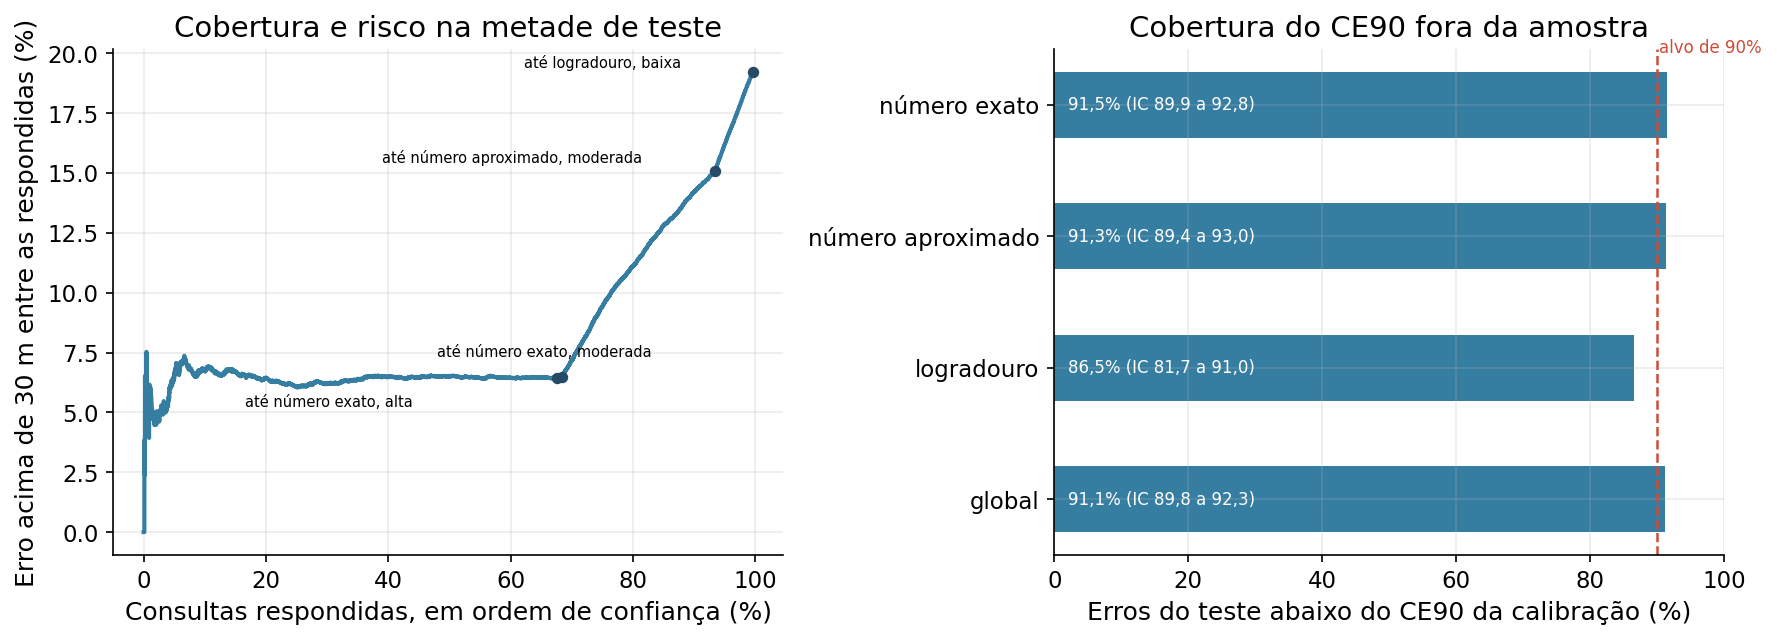

In [6]:
ordem = tes.assign(r=tes.nivel.map(ordem_nivel)*3+tes.confianca.map(ordem_conf)).sort_values('r')
cob = np.arange(1, len(ordem)+1)/len(resp[resp.metade == 'teste'])
risco = np.cumsum(ordem.erro_m.to_numpy() > 30)/np.arange(1, len(ordem)+1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
axes[0].plot(100*cob, 100*risco, color='#367EA1', linewidth=2)
nome_nivel = {'numero_exato': 'número exato', 'numero_aproximado': 'número aproximado', 'logradouro': 'logradouro'}
deslocamento = {('numero_exato','alta'): (-150, -14), ('numero_exato','moderada'): (-60, 10), ('numero_aproximado','moderada'): (-160, 4), ('logradouro','baixa'): (-110, 2)}
for (nv, cf), g in ordem.groupby(['nivel','confianca'], sort=False):
    pos = ordem.index.get_indexer(g.index).max()
    axes[0].scatter(100*cob[pos], 100*risco[pos], color='#264B67', s=20, zorder=3)
    axes[0].annotate(f'até {nome_nivel[nv]}, {cf}', (100*cob[pos], 100*risco[pos]), fontsize=7, xytext=deslocamento.get((nv, cf), (4, -10)), textcoords='offset points')
axes[0].set(xlabel='Consultas respondidas, em ordem de confiança (%)', ylabel='Erro acima de 30 m entre as respondidas (%)', title='Cobertura e risco na metade de teste')
cv = cobertura.set_index('grupo')
y = np.arange(len(cv))
axes[1].barh(y, cv.cobertura_ce90_pct, color='#367EA1', height=.5)
axes[1].axvline(90, color='#D04A38', linewidth=1.2, linestyle='--'); axes[1].text(90.3, len(cv)-.6, 'alvo de 90%', color='#D04A38', fontsize=8)
for i, (v, ic) in enumerate(zip(cv.cobertura_ce90_pct, cv.ic_ce90)):
    axes[1].text(2, i, f'{v:.1f}% (IC {ic})'.replace('.', ','), va='center', color='white', fontsize=8)
axes[1].set_yticks(y, [nome_nivel.get(s, s) for s in cv.index]); axes[1].set_xlim(0, 100)
axes[1].set(xlabel='Erros do teste abaixo do CE90 da calibração (%)', title='Cobertura do CE90 fora da amostra')
for ax in axes: ax.spines[['top','right']].set_visible(False); ax.grid(alpha=.25)
fig.tight_layout(); fig.savefig(F/'nb17_teste_independente.png', dpi=200); plt.show()

A taxa de resposta é de 99,6% no teste, com 68,5% das consultas em número exato, 25,0% em número aproximado e 6,1% em logradouro. As 196 recusas das duas metades foram respostas 404 sem candidato. Elas entram no denominador da curva de cobertura e risco, mas não no da cobertura do P90, que só pode ser medida onde houve resposta.

A AUC para erro acima de 30 m é de 0,804 no teste para o nível de precisão, com intervalo de 0,786 a 0,821, e de 0,802 para a classe de confiança. Na amostra de desenvolvimento, as duas eram 0,804 e 0,803, e na metade de calibração 0,789 e 0,788. A discriminação se mantém fora da amostra que orientou os limiares. A classe de confiança continua sem acrescentar discriminação ao nível de precisão.

A tabela de desenvolvimento do NB14 era moderadamente otimista no nível exato: P90 de 20,98 m contra 22,10 m no teste para a confiança alta, e erro acima de 30 m de 5,8% contra 6,5%. No número aproximado ela era pessimista, com P90 de 2.229,93 m contra 377,78 m, porque esse escalão tem cauda pesada e poucos casos extremos mudam o quantil. A curva de cobertura e risco mostra que o risco fica perto de 6,5% até os 68% de consultas em número exato e sobe depois, até 19,2% no conjunto das respondidas.

## 5. Tabela candidata no formato da API

A tabela estimada na metade de calibração é gravada com os metadados que o validador da API exige: código do município, versão dos dados e da política lidas das respostas, rota `geocode`, amostra `teste_independente` e fonte de referência. O próprio `Calibrador` da API carrega o arquivo, o que verifica tipos, ordem dos quantis, coerência das taxas e a linha global. A instalação da tabela na API não é feita aqui. Ela troca o estado da resposta de declarada para calibrada, e a cobertura medida na Seção 3 é o que a sustenta.

In [7]:
cand = tabela.copy()
cand.insert(0, 'codigo_municipio', '3106200')
cand['n'] = cand.n.astype(int)
for c in ['erro_mediano_m','erro_ce90_m','acima_30_pct','acima_100_pct']: cand[c] = cand[c].round(2)
cand['versao_dados'] = VERSAO_DADOS; cand['versao_politica'] = VERSAO_POLITICA
cand['tipo_consulta'] = 'geocode'; cand['amostra'] = 'teste_independente'
cand['fonte_referencia'] = 'BHMap, pontos vistoriados (com ou sem placa), metade de calibracao por blocos de 2 km, NB17'
destino = T/'nb17_calibracao_candidata.csv'
cand.to_csv(destino, index=False)
calibrador = carregar(destino)
print('municipios aceitos pelo validador da API:', calibrador.municipios_calibrados)
assert calibrador.municipios_calibrados == ['3106200']
from src.api.schemas import NivelPrecisao, ClasseConfianca
print(calibrador.consultar('3106200', NivelPrecisao('numero_exato'), ClasseConfianca('alta'), versao_dados=VERSAO_DADOS, versao_politica=VERSAO_POLITICA))
manifesto = {'data': '2026-10-02', 'notebook': '17_teste_operacional_independente.ipynb', 'api': API, 'saude': saude,
             'versao_politica': VERSAO_POLITICA, 'versao_dados': VERSAO_DADOS, 'bloco_m': BLOCO_M, 'n_por_metade': N_POR_METADE,
             'semente': RANDOM_STATE, 'segundos': round(decorrido, 1), 'tabela_instalada_na_imagem': False,
             'bhmap_sha256': hashlib.sha256((P/'bhmap_bh.parquet').read_bytes()).hexdigest(), 'populacao': 'pontos vistoriados'}
(T/'nb17_manifesto.json').write_text(json.dumps(manifesto, ensure_ascii=False, indent=2), encoding='utf-8')
print(cand.to_string(index=False))

municipios aceitos pelo validador da API: ['3106200']
status=<StatusCalibracao.CALIBRADA: 'calibrada'> referencia='BHMap, pontos vistoriados (com ou sem placa), metade de calibracao por blocos de 2 km, NB17. 19.884 endereços medidos' base='nivel+confianca' n_amostra=13048 erro_mediano_m=8.74 erro_ce90_m=24.39 acima_de_30_m_pct=7.66 acima_de_100_m_pct=3.26 versao_dados='08dc7c7c149e767cebad336cef11fd73d2c061ec2a3ff830dd06f61b09c37d78' versao_politica='343916723a8e9266725be6aaa12068cbd7c3ca242c524b1cb4ad0c304266dac4' tipo_consulta='geocode' amostra='teste_independente'
codigo_municipio             nivel confianca            base     n  erro_mediano_m  erro_ce90_m  acima_30_pct  acima_100_pct                                                     versao_dados                                                  versao_politica tipo_consulta            amostra                                                                            fonte_referencia
         3106200                              

## Conclusão

A política de resposta congelada foi avaliada em 20.000 endereços novos, separados da amostra de ajuste por endereço e da calibração por bloco espacial. A tradução da classe em metros vale fora da amostra. O P90 da calibração cobre 91,1% dos erros do teste (intervalo de 89,8% a 92,3%), e a mediana cobre 50,8%. A discriminação fica em 0,804 no teste, a mesma do desenvolvimento, e a classe de confiança continua sem ganho sobre o nível de precisão.

A tabela candidata da Seção 5 é a primeira com teste independente compatível com a rota, a política e a carga em execução, e o validador da API a aceita. Os limites permanecem. A referência são os pontos vistoriados do BHMap, que não são verdade de campo, a independência em relação ao desenvolvimento é por endereço e não por espaço, e o resultado vale para Belo Horizonte e para esta versão dos dados e da política.

O [NB18](18_restricao_territorial.ipynb) retoma a sequência analítica com a restrição territorial do pareamento.